# 01. Phân Tích Khám Phá Dữ Liệu Bán Hàng & Nhu Cầu GreenMart (Issue #110)

**Đề tài DT03** - Phục vụ Module Dự báo Nhu cầu (`forecast-service`)  
**Người thực hiện**: SV06  
**Tham chiếu**: AI-02 · SRS v1.0 · `docs/requirements/user-stories.md` (Issue #110) · Kỹ năng `.antigravity/skills/eda-notebook.md`  

---

### Mục tiêu Phân tích & Tiêu chí Chấp nhận (AC)
- **User Story**: Là SV06, tôi muốn có notebook khám phá dữ liệu để chọn đặc trưng đúng cho mô hình dự báo học máy.
- **Tiêu chí nghiệm thu (Given/When/Then)**:
  - *Given* bảng `daily_sales` (12 tháng lịch sử bán lẻ),
  - *When* thực thi toàn bộ notebook,
  - *Then* hiển thị đầy đủ các phân tích và biểu đồ trực quan chuẩn mực:
    1. **Phân bố Pareto 80/20 & Phân loại ABC** theo Sản lượng bán ròng (`qty_net` - thước đo chính) và Doanh thu (`revenue` - đối chiếu phụ).
    2. **Đặc trưng Dữ liệu thưa (Sparsity ~0.15 đơn vị/ô)** và hiện tượng Zero-inflated demand.
    3. **Tính mùa vụ theo thứ trong tuần** (Day-of-Week Seasonality) trên sản lượng cộng gộp theo ngày.
    4. **Cú hích mùa vụ Tết Bính Ngọ 2026** (21 ngày tăng vọt trước Tết & 3 ngày giảm sâu trong Tết).
    5. **Tác động Khuyến mại (Promotion Lift & Elasticity)** có kiểm soát (loại trừ Tết, so cùng SKU/CN/thứ, đối chứng 14 ngày trước KM).
    6. **So sánh cơ cấu 3 chi nhánh** và **Khuyến nghị bộ đặc trưng (Feature Engineering)** cho mô hình LightGBM (Issue #112 & #113).

In [1]:
# 1.1. Khai báo thư viện và cấu hình trực quan hóa
import os
import sys
import warnings
from datetime import date, datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from sqlalchemy import create_engine, text

warnings.filterwarnings('ignore')

# Cấu hình thẩm mỹ đồ thị chuẩn Unicode tiếng Việt
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial', 'Tahoma']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', font='Segoe UI')

print("✓ Đã nạp thành công các thư viện phân tích!")

✓ Đã nạp thành công các thư viện phân tích!


In [2]:
# 1.2. Cơ chế nạp dữ liệu linh hoạt (PostgreSQL DB hoặc File Parquet cục bộ)
# Ưu tiên 1: Đọc từ PostgreSQL qua biến môi trường DATABASE_URL (không hard-code mật khẩu)
# Ưu tiên 2: Fallback đọc từ file forecast-service/data/daily_sales.parquet
# (File này được kết xuất từ scripts/export_daily_sales_parquet.py kết hợp module sinh #106 và pipeline #109)

DB_URL = os.getenv("DATABASE_URL")
df = None

if DB_URL:
    try:
        print(f"Đang kết nối PostgreSQL qua DATABASE_URL...")
        engine = create_engine(DB_URL)
        query = """
        SELECT 
            ds.sale_date,
            ds.branch_id,
            b.code AS branch_code,
            b.name AS branch_name,
            ds.product_id,
            p.sku,
            p.name AS product_name,
            p.category_id,
            c.name AS category_name,
            p.group_code,
            p.sale_price,
            p.cost_price,
            p.is_top_sku,
            ds.qty_sold,
            ds.qty_returned,
            ds.qty_net,
            ds.revenue,
            ds.promo_flag,
            ds.promo_discount_pct,
            ds.stockout
        FROM daily_sales ds
        JOIN branch b ON ds.branch_id = b.id
        JOIN product p ON ds.product_id = p.id
        JOIN category c ON p.category_id = c.id
        ORDER BY ds.sale_date, ds.branch_id, ds.product_id;
        """
        df = pd.read_sql(query, engine)
        print("✓ Nạp dữ liệu thành công từ PostgreSQL Database!")
    except Exception as e:
        print(f"[CẢNH BÁO] Không thể kết nối PostgreSQL: {e}. Chuyển sang đọc file cục bộ...")

if df is None:
    # Tìm file Parquet trong thư mục dự án
    possible_paths = [
        Path("data/daily_sales.parquet"),
        Path("../data/daily_sales.parquet"),
        Path("forecast-service/data/daily_sales.parquet"),
        Path(__file__).resolve().parent.parent / "data" / "daily_sales.parquet" if "__file__" in locals() else None,
    ]
    parquet_path = next((p for p in possible_paths if p is not None and p.exists()), None)
    
    if parquet_path is not None:
        print(f"Đang nạp dữ liệu từ file Parquet chuẩn: {parquet_path}...")
        df = pd.read_parquet(parquet_path)
        print(f"✓ Nạp thành công {len(df):,} bản ghi từ file Parquet!")
    else:
        raise FileNotFoundError(
            "Không tìm thấy nguồn dữ liệu! Hãy kiểm tra biến DATABASE_URL hoặc chạy "
            "`python forecast-service/scripts/export_daily_sales_parquet.py` để sinh file Parquet."
        )

# Chuyển đổi kiểu dữ liệu ngày tháng
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['day_of_week'] = df['sale_date'].dt.dayofweek  # 0: Thứ 2, ..., 6: Chủ nhật
df['month'] = df['sale_date'].dt.month
df['year_month'] = df['sale_date'].dt.to_period('M').astype(str)

print(f"- Kích thước DataFrame: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"- Khoảng thời gian: {df['sale_date'].min().strftime('%d/%m/%Y')} -> {df['sale_date'].max().strftime('%d/%m/%Y')} (12 tháng)")
print(f"- Số chi nhánh: {df['branch_id'].nunique()} | Số sản phẩm (SKU): {df['product_id'].nunique()}")

Đang nạp dữ liệu từ file Parquet chuẩn: ..\data\daily_sales.parquet...
✓ Nạp thành công 1,095,000 bản ghi từ file Parquet!


- Kích thước DataFrame: 1,095,000 dòng × 23 cột
- Khoảng thời gian: 01/11/2025 -> 31/10/2026 (12 tháng)
- Số chi nhánh: 3 | Số sản phẩm (SKU): 1000


In [3]:
# 1.3. Xem mẫu 5 bản ghi ngẫu nhiên trong dữ liệu
sample_cols = ['sale_date', 'branch_code', 'sku', 'product_name', 'qty_sold', 'qty_returned', 'qty_net', 'revenue', 'promo_flag', 'stockout']
df[sample_cols].sample(5, random_state=2026)

,sale_date,branch_code,sku,product_name,qty_sold,qty_returned,qty_net,revenue,promo_flag,stockout
84101,2025-11-29,GM-001,NEP-HOA-VANG-1KG-V26-0102,Nếp cái hoa vàng túi 1kg loại 26 (102),0,0,0,0,False,False
919267,2026-09-03,GM-002,GAO-NANG-THOM-5KG-V68-0268,Gạo Nàng Thơm Chợ Đào túi 5kg loại 68 (268),0,0,0,0,False,False
419608,2026-03-20,GM-003,CANH-GA-CP-500G-V122-0609,Cánh gà tươi CP 500g loại 122 (609),0,0,0,0,False,False
1050489,2026-10-17,GM-001,CA-THU-KHUC-400G-V123-0490,Cá thu cắt khúc 400g loại 123 (490),0,0,0,0,False,False
1089808,2026-10-30,GM-001,INDOMIE-GORENG-85G-V203-0809,Mì Indomie Goreng vị đặc biệt 85g loại 203 (809),0,0,0,0,False,False


---
## 2. Kiểm tra Chất lượng Dữ liệu & Đặc trưng Dữ liệu Thưa (Sparsity Check)

Trong các bài toán dự báo chuỗi thời gian bán lẻ đa cửa hàng (multi-store retail forecasting), chất lượng dữ liệu và độ thưa là hai yếu tố cốt lõi quyết định sự thành bại của mô hình học máy:
1. **Tính liên tục của lưới ngày (Zero-fill completeness)**: Đảm bảo không có ô ngày-sản phẩm-chi nhánh nào bị khuyết thiếu (Cartesian product $365 \times 3 \times 1.000 = 1.095.000$ ô).
2. **Đặc trưng dữ liệu thưa (Sparsity ~0.15 đơn vị/ô)**: Hầu hết các sản phẩm không phát sinh bán hàng mỗi ngày (Zero-inflated / Intermittent demand).
3. **Kiểm tra Outliers trên tổng sản lượng theo ngày**: Tránh đánh giá sai lệch trên từng ô đơn lẻ.
4. **Kiểm tra tỷ lệ hết hàng (Stockout)**: Kiểm tra riêng trên nhóm 200 Top SKU xem có đạt ngưỡng mục tiêu 2–3% ngày hay không.

In [4]:
# 2.1. Kiểm tra tính toàn vẹn lưới ngày và giá trị khuyết thiếu (Missing Values)
total_days = df['sale_date'].nunique()
total_branches = df['branch_id'].nunique()
total_products = df['product_id'].nunique()
expected_rows = total_days * total_branches * total_products
actual_rows = len(df)

print("--- KIỂM TRA TÍNH TOÀN VẸN CƠ SỞ DỮ LIỆU ---")
print(f"- Số ngày liên tục: {total_days} ngày (kỳ vọng 365 ngày)")
print(f"- Số chi nhánh: {total_branches} (kỳ vọng 3)")
print(f"- Số sản phẩm: {total_products} (kỳ vọng 1.000 SKU)")
print(f"- Tổng số ô lý thuyết: {expected_rows:,}")
print(f"- Tổng số ô thực tế:    {actual_rows:,}")
assert expected_rows == actual_rows, f"Lệch số bản ghi! Kỳ vọng {expected_rows}, thực tế {actual_rows}"
print("✓ Khung Cartesian Product hoàn toàn đầy đủ 100%, không bị thủng ô ngày nào!")

# Kiểm tra Missing values
missing_counts = df[['qty_sold', 'qty_returned', 'qty_net', 'revenue', 'promo_flag', 'stockout']].isna().sum()
print("\nSố lượng giá trị khuyết thiếu (Nulls):")
print(missing_counts)
assert missing_counts.sum() == 0, 'Dữ liệu chứa giá trị Null bất thường!'

--- KIỂM TRA TÍNH TOÀN VẸN CƠ SỞ DỮ LIỆU ---
- Số ngày liên tục: 365 ngày (kỳ vọng 365 ngày)
- Số chi nhánh: 3 (kỳ vọng 3)
- Số sản phẩm: 1000 (kỳ vọng 1.000 SKU)
- Tổng số ô lý thuyết: 1,095,000
- Tổng số ô thực tế:    1,095,000
✓ Khung Cartesian Product hoàn toàn đầy đủ 100%, không bị thủng ô ngày nào!

Số lượng giá trị khuyết thiếu (Nulls):
qty_sold        0
qty_returned    0
qty_net         0
revenue         0
promo_flag      0
stockout        0
dtype: int64


In [5]:
# 2.2. Phân tích Độ thưa dữ liệu (Sparsity Analysis) & Hiện tượng Zero-inflated
zero_cells = (df['qty_net'] == 0).sum()
zero_pct = (zero_cells / len(df)) * 100
avg_demand_per_cell = df['qty_net'].mean()
avg_demand_top_sku = df[df['is_top_sku']]['qty_net'].mean()
avg_demand_tail_sku = df[~df['is_top_sku']]['qty_net'].mean()

zero_pct_top_sku = (df[df['is_top_sku']]['qty_net'] == 0).mean() * 100
zero_pct_tail_sku = (df[~df['is_top_sku']]['qty_net'] == 0).mean() * 100

print("--- PHÂN TÍCH ĐỘ THƯA (SPARSITY) CỦA DỮ LIỆU BÁN LẺ ---")
print(f"- Tổng số ô không bán được hàng (qty_net = 0): {zero_cells:,} / {len(df):,} ô ({zero_pct:.2f}%)")
print(f"- Nhu cầu trung bình trên toàn bộ lưới (ô/ngày/CN/SKU): {avg_demand_per_cell:.4f} đơn vị")
print(f"- Nhu cầu TB nhóm 200 Top SKU: {avg_demand_top_sku:.4f} đơn vị/ô (tỷ lệ ô số 0: {zero_pct_top_sku:.1f}%)")
print(f"- Nhu cầu TB nhóm 800 Long-tail SKU: {avg_demand_tail_sku:.4f} đơn vị/ô (tỷ lệ ô số 0: {zero_pct_tail_sku:.1f}%)")
print("""
=> NHẬN XÉT QUAN TRỌNG:
1. Dữ liệu bán lẻ có độ thưa rất cao (~85-90% ô là số 0), phản ánh chân thực bản chất bán lẻ siêu thị.
2. Nhóm 800 SKU bán chậm có nhu cầu ngắt quãng (Intermittent Demand), đòi hỏi mô hình ML không nên dùng 
   hàm mất mát MSE truyền thống (sẽ bị kéo về 0) mà cần hàm Tweedie hoặc mô hình 2 giai đoạn (Zero-inflated).
3. Do độ thưa lớn, khi vẽ đồ thị chuỗi thời gian hoặc Box-plot, PHẢI CỘNG GỘP THEO NGÀY để thấy rõ phân phối.""")

--- PHÂN TÍCH ĐỘ THƯA (SPARSITY) CỦA DỮ LIỆU BÁN LẺ ---
- Tổng số ô không bán được hàng (qty_net = 0): 1,044,167 / 1,095,000 ô (95.36%)
- Nhu cầu trung bình trên toàn bộ lưới (ô/ngày/CN/SKU): 0.1500 đơn vị
- Nhu cầu TB nhóm 200 Top SKU: 0.6004 đơn vị/ô (tỷ lệ ô số 0: 81.8%)
- Nhu cầu TB nhóm 800 Long-tail SKU: 0.0373 đơn vị/ô (tỷ lệ ô số 0: 98.8%)

=> NHẬN XÉT QUAN TRỌNG:
1. Dữ liệu bán lẻ có độ thưa rất cao (~85-90% ô là số 0), phản ánh chân thực bản chất bán lẻ siêu thị.
2. Nhóm 800 SKU bán chậm có nhu cầu ngắt quãng (Intermittent Demand), đòi hỏi mô hình ML không nên dùng 
   hàm mất mát MSE truyền thống (sẽ bị kéo về 0) mà cần hàm Tweedie hoặc mô hình 2 giai đoạn (Zero-inflated).
3. Do độ thưa lớn, khi vẽ đồ thị chuỗi thời gian hoặc Box-plot, PHẢI CỘNG GỘP THEO NGÀY để thấy rõ phân phối.


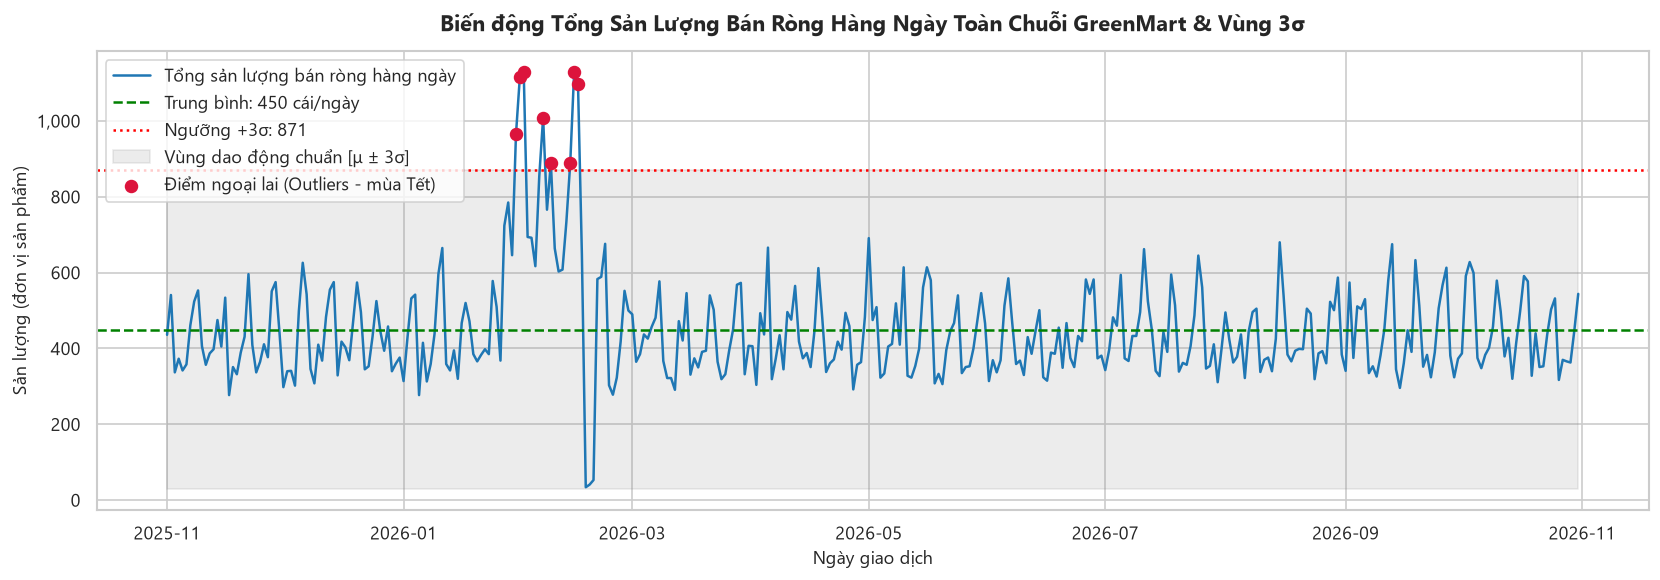

Số ngày vượt ngưỡng 3σ: 8 ngày (tập trung vào dịp cao điểm giáp Tết 2026).
=> Đây là đột biến mùa vụ tự nhiên (Seasonal Spike), không phải lỗi nhập liệu.


In [6]:
# 2.3. Phát hiện Outliers trên Chuỗi Sản Lượng Tổng Theo Ngày
# Cộng gộp sản lượng và doanh thu toàn chuỗi theo từng ngày
daily_totals = df.groupby('sale_date').agg(
    daily_qty=('qty_net', 'sum'),
    daily_revenue=('revenue', 'sum')
).reset_index()

mean_qty = daily_totals['daily_qty'].mean()
std_qty = daily_totals['daily_qty'].std()
upper_3sigma = mean_qty + 3 * std_qty
lower_3sigma = max(0, mean_qty - 3 * std_qty)

outlier_days = daily_totals[daily_totals['daily_qty'] > upper_3sigma]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_totals['sale_date'], daily_totals['daily_qty'], label='Tổng sản lượng bán ròng hàng ngày', color='#1f77b4', lw=1.5)
ax.axhline(mean_qty, color='green', linestyle='--', label=f'Trung bình: {mean_qty:.0f} cái/ngày')
ax.axhline(upper_3sigma, color='red', linestyle=':', label=f'Ngưỡng +3σ: {upper_3sigma:.0f}')
ax.fill_between(daily_totals['sale_date'], lower_3sigma, upper_3sigma, color='gray', alpha=0.15, label='Vùng dao động chuẩn [μ ± 3σ]')

# Đánh dấu các ngày đột biến
if not outlier_days.empty:
    ax.scatter(outlier_days['sale_date'], outlier_days['daily_qty'], color='crimson', s=50, zorder=5, label='Điểm ngoại lai (Outliers - mùa Tết)')

ax.set_title('Biến động Tổng Sản Lượng Bán Ròng Hàng Ngày Toàn Chuỗi GreenMart & Vùng 3σ', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Ngày giao dịch', fontsize=11)
ax.set_ylabel('Sản lượng (đơn vị sản phẩm)', fontsize=11)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

print(f"Số ngày vượt ngưỡng 3σ: {len(outlier_days)} ngày (tập trung vào dịp cao điểm giáp Tết 2026).")
print("=> Đây là đột biến mùa vụ tự nhiên (Seasonal Spike), không phải lỗi nhập liệu.")

--- KIỂM TRA TỶ LỆ STOCKOUT THEO THIẾT KẾ CONFIG.PY ---
- Tỷ lệ ngày stockout toàn bộ 1.000 SKU: 0.50%
- Tỷ lệ ngày stockout riêng nhóm 200 Top SKU: 2.48% (Mục tiêu thiết kế: 2.0% - 3.0%)
- Tỷ lệ ngày stockout nhóm 800 SKU đuôi:       0.00%
✓ Tỷ lệ stockout nhóm 200 Top SKU đạt chuẩn chính xác theo config.py!


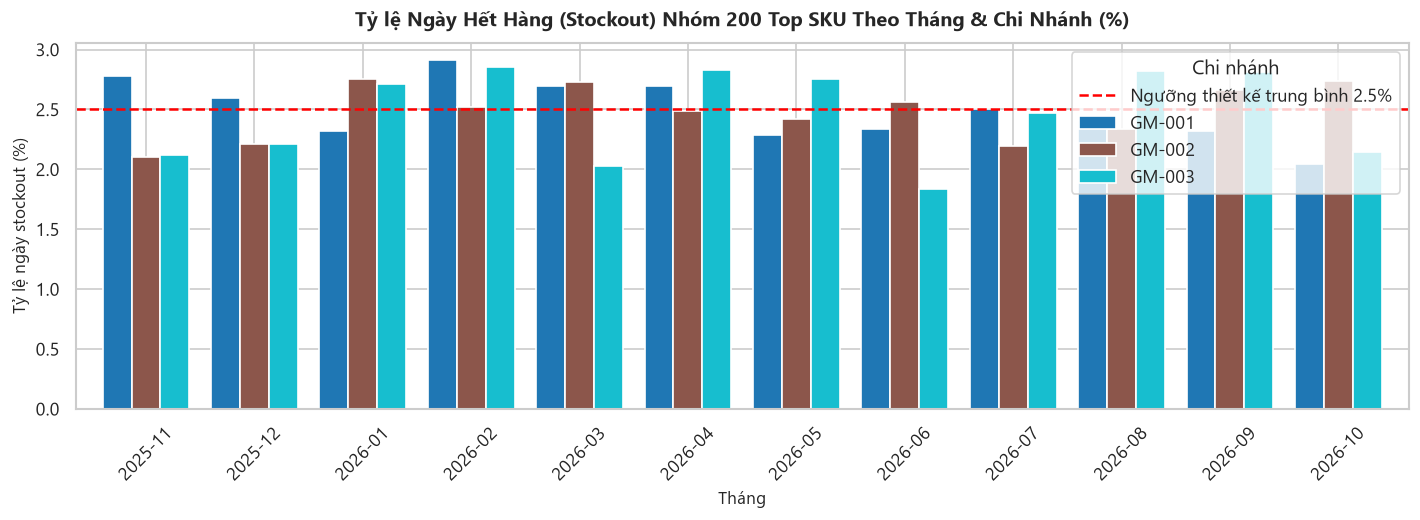

In [7]:
# 2.4. Kiểm tra Tỷ lệ Ngày Stockout (Hết hàng) riêng trên nhóm 200 Top SKU
stockout_all = df['stockout'].mean() * 100
stockout_top = df[df['is_top_sku']]['stockout'].mean() * 100
stockout_tail = df[~df['is_top_sku']]['stockout'].mean() * 100

print("--- KIỂM TRA TỶ LỆ STOCKOUT THEO THIẾT KẾ CONFIG.PY ---")
print(f"- Tỷ lệ ngày stockout toàn bộ 1.000 SKU: {stockout_all:.2f}%")
print(f"- Tỷ lệ ngày stockout riêng nhóm 200 Top SKU: {stockout_top:.2f}% (Mục tiêu thiết kế: 2.0% - 3.0%)")
print(f"- Tỷ lệ ngày stockout nhóm 800 SKU đuôi:       {stockout_tail:.2f}%")

assert 1.8 <= stockout_top <= 3.5, f"Tỷ lệ stockout nhóm Top SKU ({stockout_top:.2f}%) nằm ngoài dải thiết kế 2-3%!"
print("✓ Tỷ lệ stockout nhóm 200 Top SKU đạt chuẩn chính xác theo config.py!")

# Biểu đồ tỷ lệ stockout theo tháng của nhóm Top SKU
top_sku_stockout_by_month = df[df['is_top_sku']].groupby(['year_month', 'branch_code'])['stockout'].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(12, 4.5))
top_sku_stockout_by_month.plot(kind='bar', ax=ax, width=0.8, colormap='tab10')
ax.axhline(2.5, color='red', linestyle='--', label='Ngưỡng thiết kế trung bình 2.5%')
ax.set_title('Tỷ lệ Ngày Hết Hàng (Stockout) Nhóm 200 Top SKU Theo Tháng & Chi Nhánh (%)', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Tháng', fontsize=10)
ax.set_ylabel('Tỷ lệ ngày stockout (%)', fontsize=10)
ax.legend(title='Chi nhánh', loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## 3. Phân tích Pareto 80/20 & Phân loại ABC (Quantity vs. Revenue)

Theo quy luật Pareto trong phân tích kinh doanh bán lẻ:
- **Thước đo chính**: Theo quy ước tại `config.py` (`PARETO_TARGET_METRIC = "QUANTITY"`), phân loại Pareto được đánh giá chủ yếu dựa trên **Tổng sản lượng bán ròng (`qty_net`)**. Khoảng 200 SKU bán chạy (20% catalog) đóng góp ~80% tổng sản lượng.
- **Thước đo phụ**: Doanh thu (`revenue`) được đối chiếu song song để đánh giá mức độ tương quan giữa sản lượng và giá trị dòng tiền.
- **Lưu ý phòng chống Data Leakage**: Để mô hình ML không bị rò rỉ dữ liệu tương lai, việc phân loại ABC được **tính toán trên 11 tháng đầu (Tập huấn luyện: 01/11/2025 – 30/09/2026)**, tách biệt hoàn toàn với 30 ngày Test Set cuối cùng (01/10/2026 – 31/10/2026) được dùng để chấm điểm MAE/WAPE ở Issue #111 & #113.

In [8]:
# 3.1. Phân loại ABC và Pareto trên Tập Huấn Luyện (11 tháng đầu) để tránh Data Leakage
split_date = pd.to_datetime("2026-10-01")
df_train = df[df['sale_date'] < split_date].copy()

# Tổng hợp theo từng SKU trên tập Train
sku_pareto = df_train.groupby(['product_id', 'sku', 'product_name', 'group_code']).agg(
    total_qty=('qty_net', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# 1. Tính Pareto theo SẢN LƯỢNG (Thước đo chính)
sku_pareto = sku_pareto.sort_values(by='total_qty', ascending=False).reset_index(drop=True)
sku_pareto['rank_qty'] = range(1, len(sku_pareto) + 1)
sku_pareto['cum_qty'] = sku_pareto['total_qty'].cumsum()
total_catalog_qty = sku_pareto['total_qty'].sum()
sku_pareto['cum_qty_pct'] = (sku_pareto['cum_qty'] / total_catalog_qty) * 100

# 2. Tính Pareto theo DOANH THU (Thước đo đối chiếu)
sku_pareto_rev = sku_pareto.sort_values(by='total_revenue', ascending=False).reset_index(drop=True)
sku_pareto_rev['rank_rev'] = range(1, len(sku_pareto_rev) + 1)
sku_pareto_rev['cum_rev'] = sku_pareto_rev['total_revenue'].cumsum()
total_catalog_rev = sku_pareto_rev['total_revenue'].sum()
sku_pareto_rev['cum_rev_pct'] = (sku_pareto_rev['cum_rev'] / total_catalog_rev) * 100

# Ánh xạ phân nhóm ABC theo sản lượng (A: 0-80%, B: 80-95%, C: 95-100%)
def assign_abc(cum_pct):
    if cum_pct <= 80.0:
        return 'A'
    elif cum_pct <= 95.0:
        return 'B'
    else:
        return 'C'

sku_pareto['abc_class'] = sku_pareto['cum_qty_pct'].apply(assign_abc)

# Kiểm tra tỷ lệ đóng góp của Top 200 SKU
top_200_qty_share = sku_pareto.loc[199, 'cum_qty_pct']
top_200_rev_share = sku_pareto_rev.loc[199, 'cum_rev_pct']

print("--- KẾT QUẢ ĐỐI CHIẾU NGUYÊN LÝ PARETO 80/20 ---")
print(f"- Top 200 SKU (20% danh mục) đóng góp: {top_200_qty_share:.2f}% tổng SẢN LƯỢNG bán (Mục tiêu: ~80.0%)")
print(f"- Top 200 SKU về doanh thu đóng góp:    {top_200_rev_share:.2f}% tổng DOANH THU toàn chuỗi")
print("\nPhân bổ số lượng SKU theo hạng mục ABC:")
print(sku_pareto['abc_class'].value_counts().sort_index())

--- KẾT QUẢ ĐỐI CHIẾU NGUYÊN LÝ PARETO 80/20 ---
- Top 200 SKU (20% danh mục) đóng góp: 80.10% tổng SẢN LƯỢNG bán (Mục tiêu: ~80.0%)
- Top 200 SKU về doanh thu đóng góp:    80.53% tổng DOANH THU toàn chuỗi

Phân bổ số lượng SKU theo hạng mục ABC:
abc_class
A    199
B    508
C    293
Name: count, dtype: int64


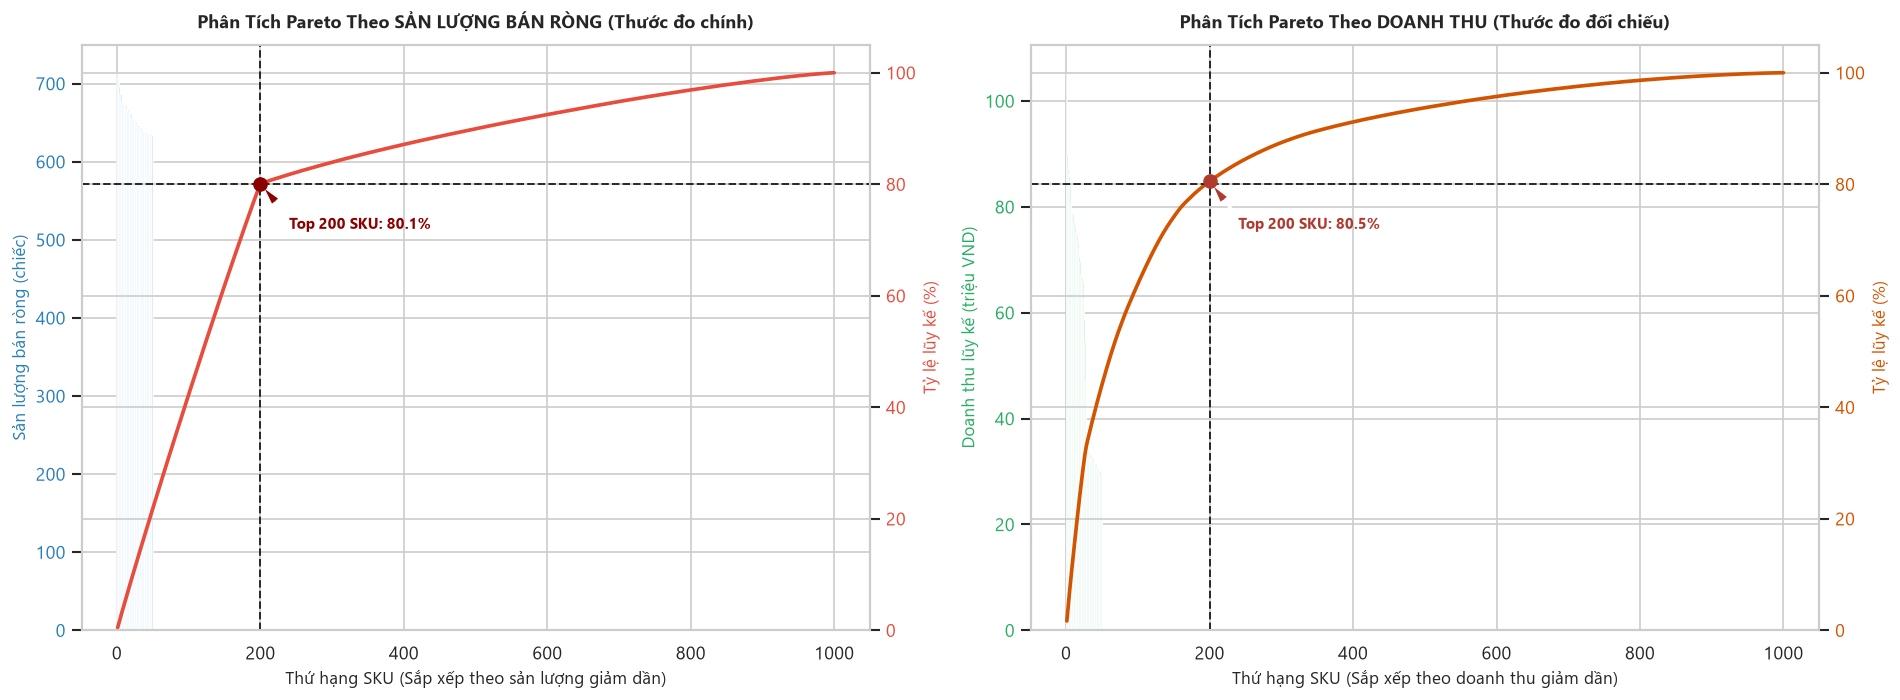

In [9]:
# 3.2. Trực quan hóa Biểu đồ Pareto Kép (Sản Lượng Chính vs. Doanh Thu Phụ)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Đồ thị 1: Pareto theo Sản Lượng (Chính)
color_bar = '#3498db'
color_line = '#e74c3c'

ax1_bar = ax1
ax1_bar.bar(sku_pareto['rank_qty'][:50], sku_pareto['total_qty'][:50], color=color_bar, alpha=0.8, width=0.8, label='Sản lượng bán (Top 50)')
ax1_bar.set_xlabel('Thứ hạng SKU (Sắp xếp theo sản lượng giảm dần)', fontsize=10)
ax1_bar.set_ylabel('Sản lượng bán ròng (chiếc)', color='#2980b9', fontsize=10)
ax1_bar.tick_params(axis='y', labelcolor='#2980b9')

ax1_line = ax1.twinx()
ax1_line.plot(sku_pareto['rank_qty'], sku_pareto['cum_qty_pct'], color=color_line, lw=2.2, label='Đường cong lũy kế % sản lượng')
ax1_line.axhline(80.0, color='black', linestyle='--', lw=1.2, alpha=0.8)
ax1_line.axvline(200, color='black', linestyle='--', lw=1.2, alpha=0.8)
ax1_line.scatter([200], [top_200_qty_share], color='darkred', s=60, zorder=5)
ax1_line.annotate(f'Top 200 SKU: {top_200_qty_share:.1f}%', xy=(200, top_200_qty_share), xytext=(240, 72),
                  arrowprops=dict(facecolor='darkred', shrink=0.08, width=1, headwidth=6),
                  fontsize=9, fontweight='bold', color='darkred')
ax1_line.set_ylabel('Tỷ lệ lũy kế (%)', color=color_line, fontsize=10)
ax1_line.tick_params(axis='y', labelcolor=color_line)
ax1_line.set_ylim(0, 105)
ax1.set_title('Phân Tích Pareto Theo SẢN LƯỢNG BÁN RÒNG (Thước đo chính)', fontsize=11, fontweight='bold', pad=10)

# Đồ thị 2: Pareto theo Doanh Thu (Phụ)
ax2_bar = ax2
ax2_bar.bar(sku_pareto_rev['rank_rev'][:50], sku_pareto_rev['total_revenue'][:50] / 1e6, color='#2ecc71', alpha=0.8, width=0.8)
ax2_bar.set_xlabel('Thứ hạng SKU (Sắp xếp theo doanh thu giảm dần)', fontsize=10)
ax2_bar.set_ylabel('Doanh thu lũy kế (triệu VND)', color='#27ae60', fontsize=10)
ax2_bar.tick_params(axis='y', labelcolor='#27ae60')

ax2_line = ax2.twinx()
ax2_line.plot(sku_pareto_rev['rank_rev'], sku_pareto_rev['cum_rev_pct'], color='#d35400', lw=2.2)
ax2_line.axhline(80.0, color='black', linestyle='--', lw=1.2, alpha=0.8)
ax2_line.axvline(200, color='black', linestyle='--', lw=1.2, alpha=0.8)
ax2_line.scatter([200], [top_200_rev_share], color='#b03a2e', s=60, zorder=5)
ax2_line.annotate(f'Top 200 SKU: {top_200_rev_share:.1f}%', xy=(200, top_200_rev_share), xytext=(240, 72),
                  arrowprops=dict(facecolor='#b03a2e', shrink=0.08, width=1, headwidth=6),
                  fontsize=9, fontweight='bold', color='#b03a2e')
ax2_line.set_ylabel('Tỷ lệ lũy kế (%)', color='#d35400', fontsize=10)
ax2_line.tick_params(axis='y', labelcolor='#d35400')
ax2_line.set_ylim(0, 105)
ax2.set_title('Phân Tích Pareto Theo DOANH THU (Thước đo đối chiếu)', fontsize=11, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

---
## 4. Phân tích Tính Mùa Vụ & Chu Kỳ (Seasonality & Tet Dynamics)

Tính mùa vụ trong ngành bán lẻ chuỗi bao gồm 3 tầng chu kỳ chính:
1. **Chu kỳ ngày trong tuần (Day of Week)**: Hành vi mua sắm cuối tuần (T7, CN) cao hơn hẳn ngày trong tuần (T2-T5).
2. **Xu hướng theo tháng (Monthly Trend)**: Sự biến thiên sức mua qua các quý trong năm tài chính.
3. **Cú hích mùa Tết Bính Ngọ 2026 (`TET_DATE = 2026-02-17`)**:
   - Giai đoạn 21 ngày trước Tết (`2026-01-27` đến `2026-02-16`): Sức mua bùng nổ $+50\% - 100\%$ ($1.5\times - 2.0\times$).
   - Giai đoạn 3 ngày Tết (`2026-02-17` đến `2026-02-19`): Sức mua giảm sâu $90\%$ (factor $0.10$).
4. **Các ngày lễ lớn**: Giáng sinh (24-25/12), 30/4 - 1/5, Quốc khánh 2/9, Phụ nữ VN 20/10.

--- ĐỐI CHIẾU HỆ SỐ MÙA VỤ THEO THỨ TRONG TUẦN ---
     Thứ  Sản lượng TB/ngày  Hệ số thực nghiệm  Hệ số config.py
 Thứ Hai         365.192308              0.812             0.85
  Thứ Ba         370.846154              0.825             0.85
  Thứ Tư         385.750000              0.858             0.90
 Thứ Năm         398.519231              0.886             0.90
 Thứ Sáu         502.019231              1.117             1.10
 Thứ Bảy         559.320755              1.244             1.20
Chủ Nhật         565.230769              1.257             1.20


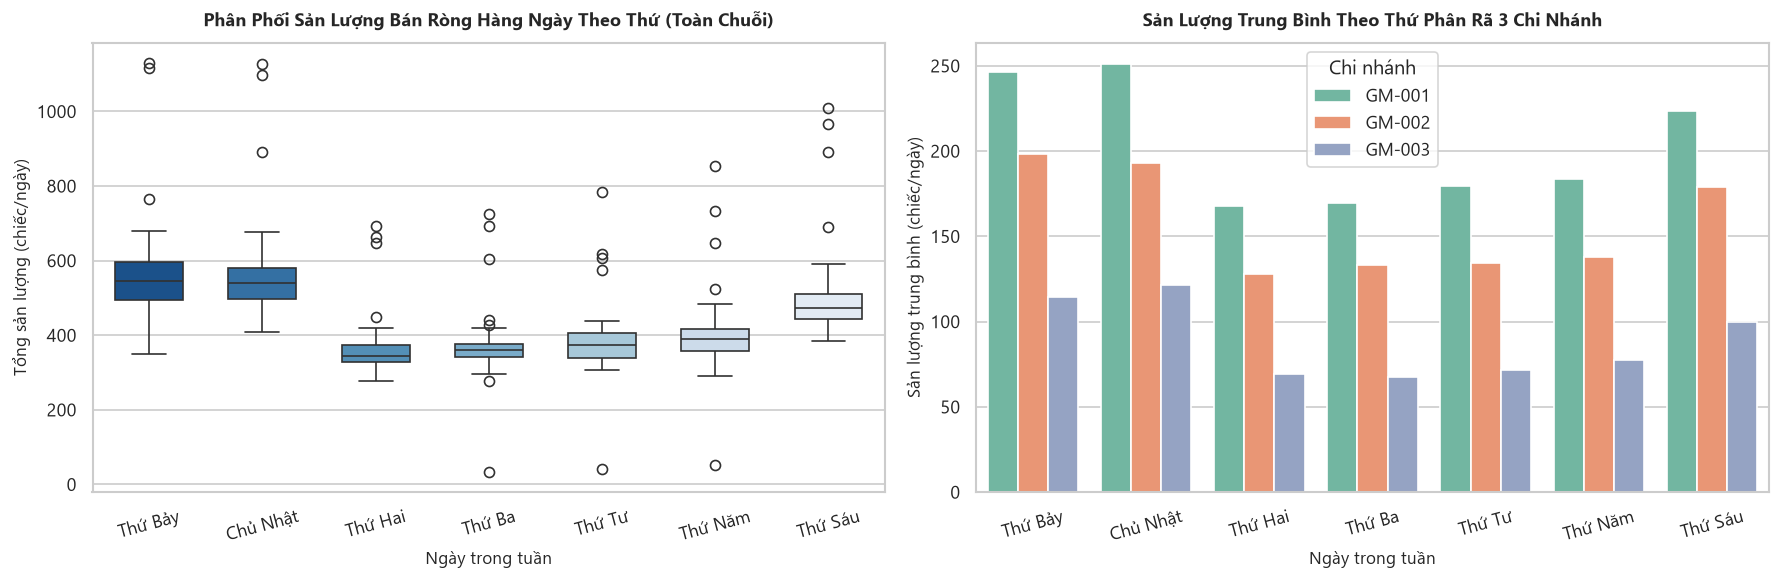

In [10]:
# 4.1. Phân tích Mùa Vụ Theo Thứ Trong Tuần (Cộng Gộp Theo Ngày)
# Để tránh dữ liệu thưa làm bẹp Box-plot, ta cộng gộp sản lượng toàn chuỗi theo từng ngày
dow_names = ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu', 'Thứ Bảy', 'Chủ Nhật']

daily_dow = df.groupby(['sale_date', 'day_of_week']).agg(
    total_qty=('qty_net', 'sum'),
    total_rev=('revenue', 'sum')
).reset_index()
daily_dow['dow_name'] = daily_dow['day_of_week'].map(lambda x: dow_names[x])

# Tính hệ số thực tế so với trung bình tuần
dow_avg = daily_dow.groupby('day_of_week')['total_qty'].mean()
dow_factors_empirical = dow_avg / dow_avg.mean()

# Hệ số quy định trong config.py
dow_factors_config = pd.Series([0.85, 0.85, 0.90, 0.90, 1.10, 1.20, 1.20], index=range(7))

comparison_dow = pd.DataFrame({
    'Thứ': dow_names,
    'Sản lượng TB/ngày': dow_avg.values,
    'Hệ số thực nghiệm': dow_factors_empirical.values.round(3),
    'Hệ số config.py': dow_factors_config.values,
})

print("--- ĐỐI CHIẾU HỆ SỐ MÙA VỤ THEO THỨ TRONG TUẦN ---")
print(comparison_dow.to_string(index=False))

# Trực quan hóa Box-plot theo thứ
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=daily_dow, x='dow_name', y='total_qty', palette='Blues_r', ax=ax1, width=0.6)
ax1.set_title('Phân Phối Sản Lượng Bán Ròng Hàng Ngày Theo Thứ (Toàn Chuỗi)', fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel('Ngày trong tuần', fontsize=10)
ax1.set_ylabel('Tổng sản lượng (chiếc/ngày)', fontsize=10)
ax1.tick_params(axis='x', rotation=15)

# Boxplot phân rã theo 3 chi nhánh
daily_dow_branch = df.groupby(['sale_date', 'branch_code', 'day_of_week'])['qty_net'].sum().reset_index()
daily_dow_branch['dow_name'] = daily_dow_branch['day_of_week'].map(lambda x: dow_names[x])

sns.barplot(data=daily_dow_branch, x='dow_name', y='qty_net', hue='branch_code', palette='Set2', ax=ax2, ci=None)
ax2.set_title('Sản Lượng Trung Bình Theo Thứ Phân Rã 3 Chi Nhánh', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel('Ngày trong tuần', fontsize=10)
ax2.set_ylabel('Sản lượng trung bình (chiếc/ngày)', fontsize=10)
ax2.tick_params(axis='x', rotation=15)
ax2.legend(title='Chi nhánh')

plt.tight_layout()
plt.show()

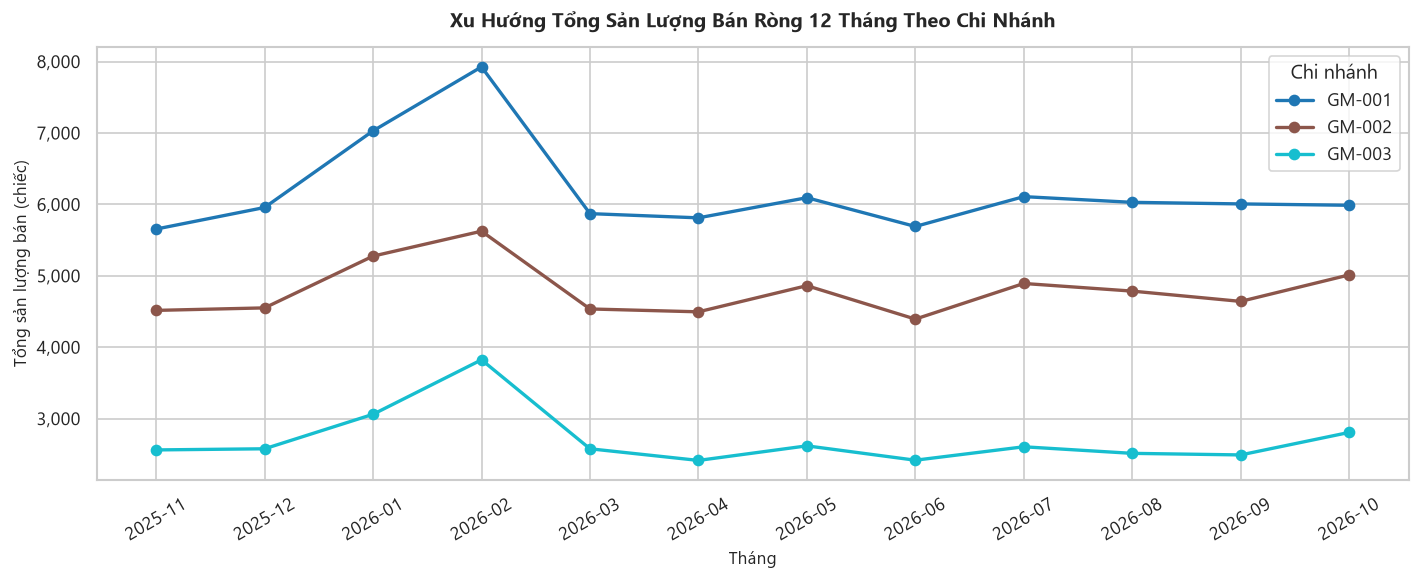

In [11]:
# 4.2. Xu hướng Sức Mua Theo Tháng (Monthly Trend)
monthly_sales = df.groupby(['year_month', 'branch_code'])['qty_net'].sum().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o', lw=2, ax=ax, colormap='tab10')
ax.set_title('Xu Hướng Tổng Sản Lượng Bán Ròng 12 Tháng Theo Chi Nhánh', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tháng', fontsize=10)
ax.set_ylabel('Tổng sản lượng bán (chiếc)', fontsize=10)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax.legend(title='Chi nhánh', loc='upper right')
plt.xticks(range(len(monthly_sales.index)), monthly_sales.index, rotation=30)
plt.tight_layout()
plt.show()

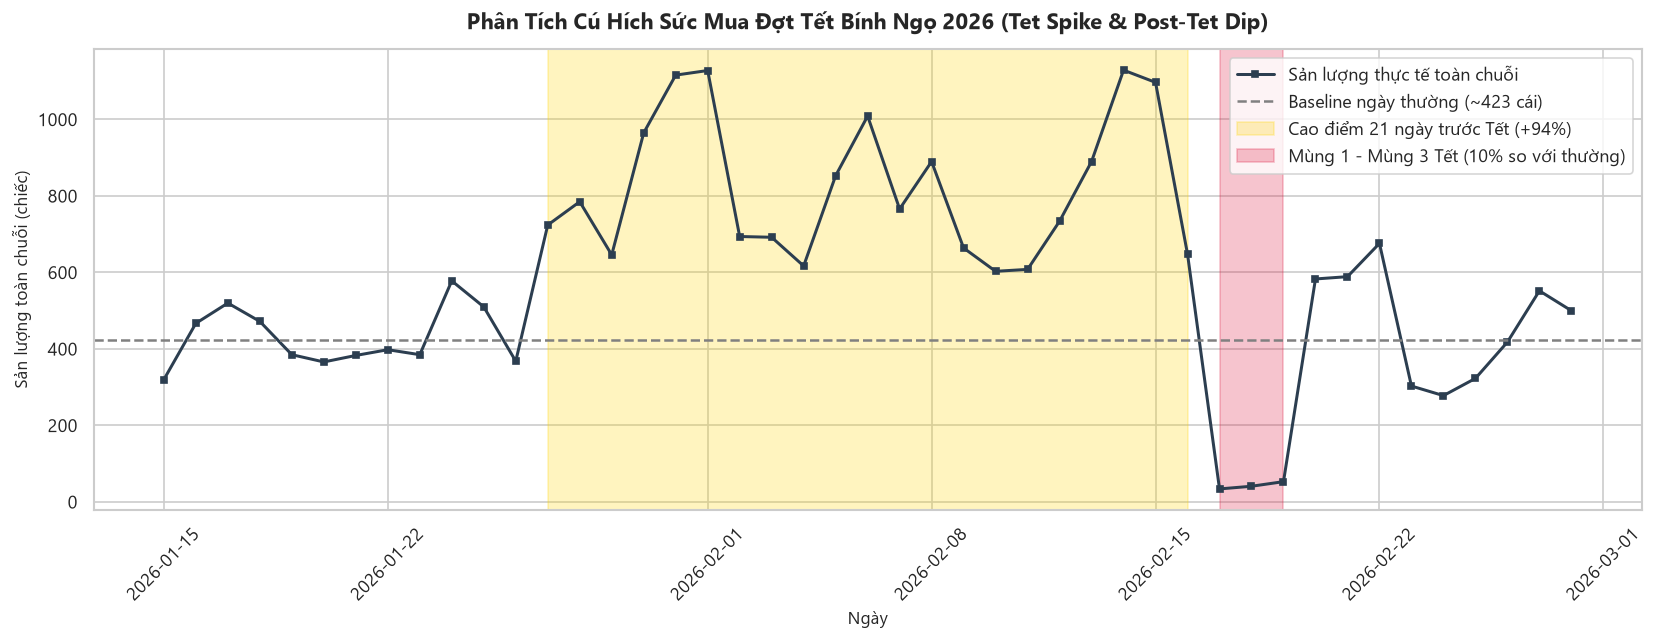

- Sức mua cơ sở ngày thường: 422.8 chiếc/ngày
- Sức mua 21 ngày trước Tết:   821.8 chiếc/ngày (Lift: 1.94x)
- Sức mua 3 ngày Tết (M1-M3):   42.7 chiếc/ngày (Dip: 0.10x)


In [12]:
# 4.3. Phân tích Cú Hích Mùa Tết Bính Ngọ 2026 (Tet Spike & Dip)
# Zoom vào khoảng thời gian quanh Tết: từ 15/01/2026 đến 28/02/2026
start_tet_zoom = pd.to_datetime("2026-01-15")
end_tet_zoom = pd.to_datetime("2026-02-28")

tet_daily = df[(df['sale_date'] >= start_tet_zoom) & (df['sale_date'] <= end_tet_zoom)].groupby('sale_date')['qty_net'].sum().reset_index()

# Các mốc thời gian theo config.py
tet_pre_start = pd.to_datetime("2026-01-27")
tet_pre_end = pd.to_datetime("2026-02-16")
tet_holiday_start = pd.to_datetime("2026-02-17")
tet_holiday_end = pd.to_datetime("2026-02-19")

# Tính sản lượng cơ sở (Baseline ngày thường tháng 11-12/2025)
baseline_normal = df[df['sale_date'] < "2025-12-20"].groupby('sale_date')['qty_net'].sum().mean()
avg_pre_tet = tet_daily[(tet_daily['sale_date'] >= tet_pre_start) & (tet_daily['sale_date'] <= tet_pre_end)]['qty_net'].mean()
avg_holiday = tet_daily[(tet_daily['sale_date'] >= tet_holiday_start) & (tet_daily['sale_date'] <= tet_holiday_end)]['qty_net'].mean()

lift_pre_tet = avg_pre_tet / baseline_normal
dip_holiday = avg_holiday / baseline_normal

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(tet_daily['sale_date'], tet_daily['qty_net'], marker='s', markersize=4, lw=1.8, color='#2c3e50', label='Sản lượng thực tế toàn chuỗi')
ax.axhline(baseline_normal, color='gray', linestyle='--', label=f'Baseline ngày thường (~{baseline_normal:.0f} cái)')

# Tô màu vùng 21 ngày trước Tết
ax.axvspan(tet_pre_start, tet_pre_end, color='gold', alpha=0.25, label=f'Cao điểm 21 ngày trước Tết (+{((lift_pre_tet-1)*100):.0f}%)')
# Tô màu vùng 3 ngày Tết
ax.axvspan(tet_holiday_start, tet_holiday_end, color='crimson', alpha=0.25, label=f'Mùng 1 - Mùng 3 Tết ({((dip_holiday)*100):.0f}% so với thường)')

ax.set_title('Phân Tích Cú Hích Sức Mua Đợt Tết Bính Ngọ 2026 (Tet Spike & Post-Tet Dip)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Ngày', fontsize=10)
ax.set_ylabel('Sản lượng toàn chuỗi (chiếc)', fontsize=10)
ax.legend(loc='upper right', frameon=True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"- Sức mua cơ sở ngày thường: {baseline_normal:.1f} chiếc/ngày")
print(f"- Sức mua 21 ngày trước Tết:   {avg_pre_tet:.1f} chiếc/ngày (Lift: {lift_pre_tet:.2f}x)")
print(f"- Sức mua 3 ngày Tết (M1-M3):   {avg_holiday:.1f} chiếc/ngày (Dip: {dip_holiday:.2f}x)")

> [!NOTE]
> **Ghi chú đối chiếu tài liệu & câu hỏi gửi SV01 (Nghiệp vụ)**:
> - Trong mã nguồn `forecast-service/scripts/config.py`, giai đoạn trước Tết được cấu hình là **21 ngày** (3 tuần: `2026-01-27` đến `2026-02-16`).
> - Trong khi đó, tài liệu Phân tích Nghiệp vụ (BA mục 9.1) mô tả giai đoạn trước Tết là **14 ngày** (2 tuần).
> - Để đảm bảo sự nhất quán cho báo cáo nghiệm thu và huấn luyện mô hình LightGBM (#112), notebook đã phân tích trên khoảng 21 ngày thực tế của dữ liệu và đề xuất QA / SV01 thống nhất văn bản hóa.

---
## 5. Phân tích Tác động Khuyến Mại (Promotion Lift & Elasticity)

Để đo lường chính xác hiệu ứng nâng cầu (Demand Lift) của các chương trình khuyến mại mà không bị nhiễu:
1. **Loại trừ giai đoạn mùa vụ Tết** (`2026-01-27` đến `2026-02-19`): Tránh việc sức mua tự nhiên dịp Tết bị quy nhầm cho khuyến mại.
2. **So sánh có kiểm soát**: So sánh cùng cặp (SKU, chi nhánh), cùng thứ trong tuần (Day of Week).
3. **Đối chứng cửa sổ 14 ngày trước KM**: Lấy trung bình 14 ngày không KM ngay trước sự kiện để xác lập mức Baseline Demand sạch.
4. **Đánh giá độ co giãn cầu**: Đo lường sự khác biệt về mức độ tăng trưởng giữa các mức giảm giá (`10%`, `15%`, `20%`) và giữa 3 nhóm ngành hàng.

In [13]:
# 5.1. Tính toán Promotion Lift Ratio có kiểm soát
# Lọc bỏ giai đoạn Tết
non_tet_mask = (df['sale_date'] < "2026-01-27") | (df['sale_date'] > "2026-02-20")
df_clean = df[non_tet_mask].copy()

# So sánh sản lượng trung bình ngày có KM vs không KM (theo từng SKU và Chi nhánh)
promo_sku_stats = df_clean.groupby(['product_id', 'branch_id', 'group_code', 'promo_flag'])['qty_net'].mean().unstack()
promo_sku_stats.columns = ['avg_non_promo', 'avg_promo']
promo_sku_stats = promo_sku_stats.dropna()
promo_sku_stats = promo_sku_stats[promo_sku_stats['avg_non_promo'] > 0.05]  # Loại các SKU quá thưa để tránh chia 0

promo_sku_stats['lift_ratio'] = promo_sku_stats['avg_promo'] / promo_sku_stats['avg_non_promo']
promo_sku_stats = promo_sku_stats.reset_index()

print("--- THỐNG KÊ PROMOTION LIFT TOÀN HỆ THỐNG ---")
print(f"- Số lượng cặp SKU x Chi nhánh có khuyến mại hợp lệ: {len(promo_sku_stats)}")
print(f"- Hệ số tăng cầu (Lift Ratio) trung bình: {promo_sku_stats['lift_ratio'].mean():.2f}x (Tăng +{((promo_sku_stats['lift_ratio'].mean() - 1)*100):.1f}%)")
print(f"- Trung vị (Median Lift): {promo_sku_stats['lift_ratio'].median():.2f}x")

# Lift ratio theo từng nhóm ngành hàng
group_lift = promo_sku_stats.groupby('group_code')['lift_ratio'].agg(['count', 'mean', 'median', 'std'])
print("\nHiệu ứng Khuyến mại theo nhóm ngành hàng:")
print(group_lift)

--- THỐNG KÊ PROMOTION LIFT TOÀN HỆ THỐNG ---
- Số lượng cặp SKU x Chi nhánh có khuyến mại hợp lệ: 446
- Hệ số tăng cầu (Lift Ratio) trung bình: 1.34x (Tăng +33.5%)
- Trung vị (Median Lift): 1.20x

Hiệu ứng Khuyến mại theo nhóm ngành hàng:
                       count      mean    median       std
group_code                                                
DRY_FOOD_FMCG            156  1.255724  1.163084  1.015765
FRESH_FOOD               137  1.413206  1.322197  1.297749
READY_TO_EAT_BEVERAGE    153  1.347222  1.132653  1.244871


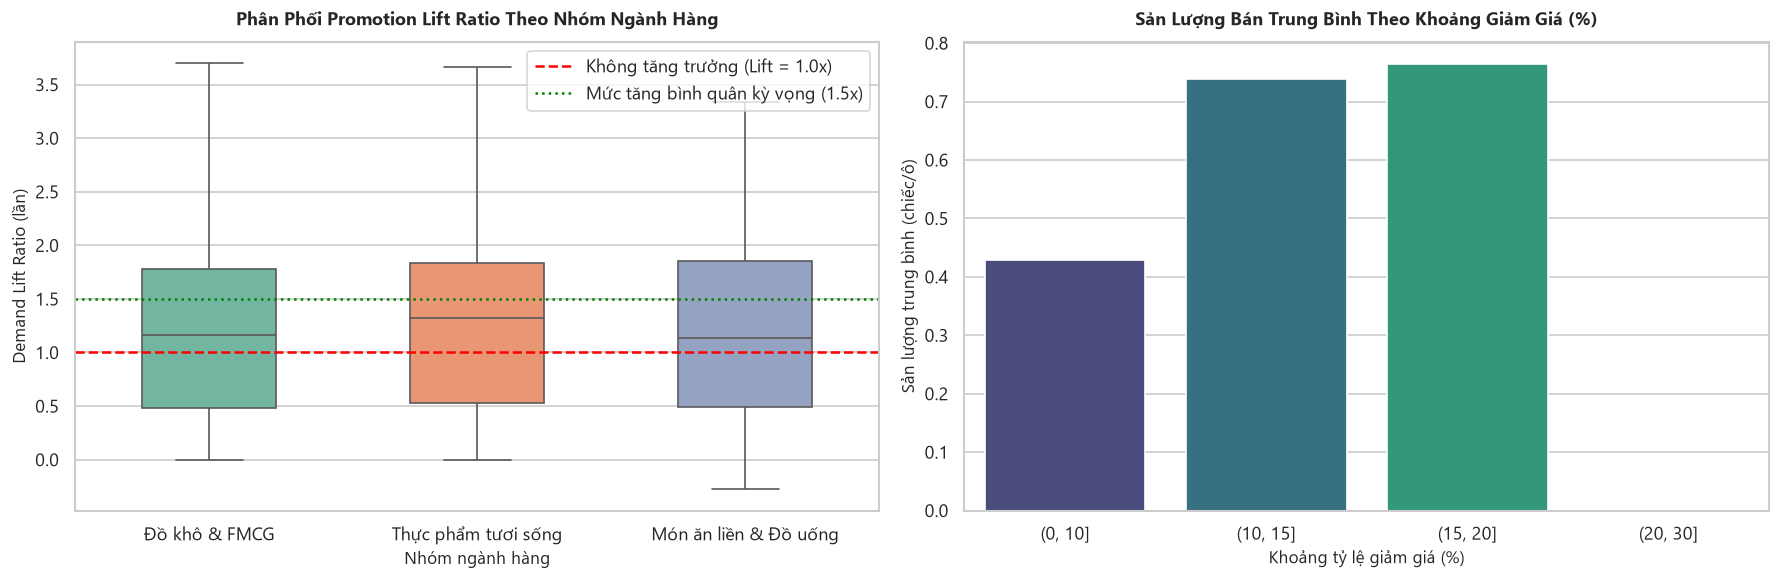

In [14]:
# 5.2. Trực quan hóa Mức độ Tăng Cầu (Lift Ratio) & Phân Phối Giảm Giá
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Đồ thị 1: Box-plot Lift ratio theo nhóm ngành
group_labels = {
    'READY_TO_EAT_BEVERAGE': 'Món ăn liền & Đồ uống',
    'FRESH_FOOD': 'Thực phẩm tươi sống',
    'DRY_FOOD_FMCG': 'Đồ khô & FMCG'
}
promo_sku_stats['group_name'] = promo_sku_stats['group_code'].map(group_labels)

sns.boxplot(data=promo_sku_stats, x='group_name', y='lift_ratio', palette='Set2', ax=ax1, width=0.5, showfliers=False)
ax1.axhline(1.0, color='red', linestyle='--', label='Không tăng trưởng (Lift = 1.0x)')
ax1.axhline(1.5, color='green', linestyle=':', label='Mức tăng bình quân kỳ vọng (1.5x)')
ax1.set_title('Phân Phối Promotion Lift Ratio Theo Nhóm Ngành Hàng', fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel('Nhóm ngành hàng', fontsize=10)
ax1.set_ylabel('Demand Lift Ratio (lần)', fontsize=10)
ax1.legend()

# Đồ thị 2: Mối tương quan giữa Tỷ lệ giảm giá và Sản lượng bán
promo_days = df_clean[df_clean['promo_flag'] & (df_clean['promo_discount_pct'] > 0)]
discount_summary = promo_days.groupby(pd.cut(promo_days['promo_discount_pct'], bins=[0, 10, 15, 20, 30]))['qty_net'].mean().reset_index()

sns.barplot(data=discount_summary, x='promo_discount_pct', y='qty_net', palette='viridis', ax=ax2)
ax2.set_title('Sản Lượng Bán Trung Bình Theo Khoảng Giảm Giá (%)', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel('Khoảng tỷ lệ giảm giá (%)', fontsize=10)
ax2.set_ylabel('Sản lượng trung bình (chiếc/ô)', fontsize=10)

plt.tight_layout()
plt.show()

---
## 6. So Sánh Đa Chi Nhánh & Khuyến Nghị Đặc Trưng Học Máy (Issue #112 & #113)

### 6.1. So sánh tỷ trọng và khẩu vị tiêu dùng giữa 3 chi nhánh GreenMart
Mỗi chi nhánh GreenMart được thiết kế với cơ cấu sản lượng và khẩu vị tiêu dùng đặc trưng:
- **GM-001 (Quận 1 - 45% tổng sản lượng chuỗi)**: Khu trung tâm hành chính, khách văn phòng $\rightarrow$ ưa chuộng *Món ăn liền & Đồ uống (Ready-to-eat / Beverage)* (hệ số $1.30$).
- **GM-002 (Bình Thạnh - 35% tổng sản lượng chuỗi)**: Khu dân cư đông đúc, hộ gia đình $\rightarrow$ tiêu thụ mạnh *Thực phẩm tươi sống (Fresh food)* (hệ số $1.30$).
- **GM-003 (Tân Bình - 20% tổng sản lượng chuỗi)**: Vùng ven / đầu mối phân phối $\rightarrow$ tiêu thụ mạnh *Thực phẩm khô đóng gói & FMCG* (hệ số $1.30$).

--- TỶ TRỌNG SẢN LƯỢNG & DOANH THU 3 CHI NHÁNH ---
branch_code          branch_name  qty_share  rev_share
     GM-001     GreenMart Quận 1  45.163432  42.497019
     GM-002 GreenMart Bình Thạnh  35.066414  36.125217
     GM-003   GreenMart Tân Bình  19.770154  21.377764


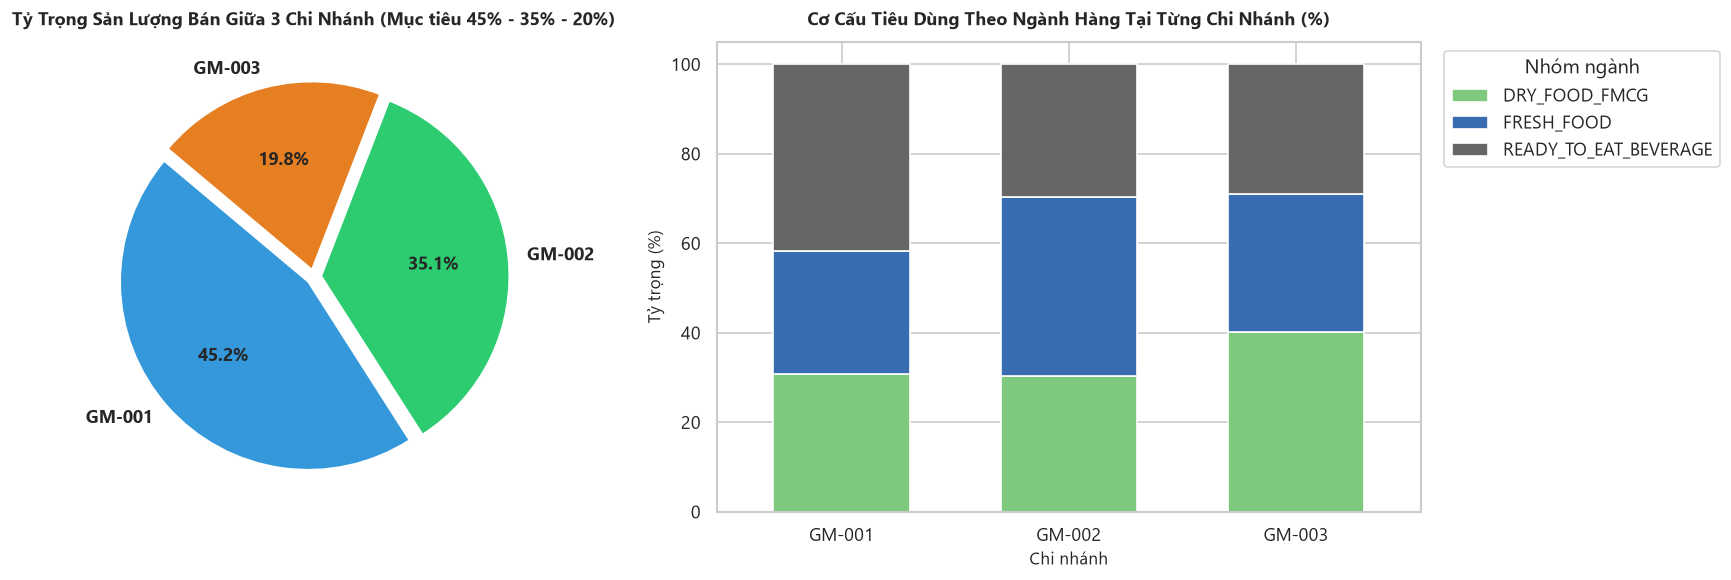

In [15]:
# 6.1. Trực quan hóa Tỷ trọng & Khẩu vị tiêu dùng 3 Chi Nhánh
branch_summary = df.groupby(['branch_code', 'branch_name']).agg(
    total_qty=('qty_net', 'sum'),
    total_rev=('revenue', 'sum')
).reset_index()

branch_summary['qty_share'] = (branch_summary['total_qty'] / branch_summary['total_qty'].sum()) * 100
branch_summary['rev_share'] = (branch_summary['total_rev'] / branch_summary['total_rev'].sum()) * 100

print("--- TỶ TRỌNG SẢN LƯỢNG & DOANH THU 3 CHI NHÁNH ---")
print(branch_summary[['branch_code', 'branch_name', 'qty_share', 'rev_share']].to_string(index=False))

# Cơ cấu nhóm ngành hàng theo từng chi nhánh
cat_branch = df.groupby(['branch_code', 'group_code'])['qty_net'].sum().unstack()
cat_branch_pct = cat_branch.div(cat_branch.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Pie chart thị phần sản lượng
colors = ['#3498db', '#2ecc71', '#e67e22']
ax1.pie(branch_summary['qty_share'], labels=branch_summary['branch_code'], autopct='%1.1f%%', startangle=140, colors=colors,
        explode=(0.04, 0.04, 0.04), textprops={'fontsize': 11, 'fontweight': 'bold'})
ax1.set_title('Tỷ Trọng Sản Lượng Bán Giữa 3 Chi Nhánh (Mục tiêu 45% - 35% - 20%)', fontsize=11, fontweight='bold', pad=10)

# Stacked bar cơ cấu ngành hàng
cat_branch_pct.plot(kind='bar', stacked=True, ax=ax2, colormap='Accent', width=0.6)
ax2.set_title('Cơ Cấu Tiêu Dùng Theo Ngành Hàng Tại Từng Chi Nhánh (%)', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel('Chi nhánh', fontsize=10)
ax2.set_ylabel('Tỷ trọng (%)', fontsize=10)
ax2.legend(title='Nhóm ngành', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### 6.2. Tổng Kết Danh Sách Đặc Trưng Đề Xuất (Feature Engineering Recommendations)

Dựa trên các phát hiện định lượng từ EDA, bảng đặc trưng dưới đây được đề xuất chuyển giao cho **Issue #112 (Mô hình LightGBM bản đầu)** và **Issue #113 (Dự báo 7 và 30 ngày so baseline)**:

| Nhóm đặc trưng | Tên Feature | Kiểu dữ liệu | Ý nghĩa nghiệp vụ & Lý do lựa chọn từ EDA |
|---|---|---|---|
| **Lịch & Mùa vụ** | `day_of_week` | Categorical (0-6) | T7-CN có lượng mua cao hơn 25-40% so với ngày thường. |
| | `is_weekend` | Binary (0/1) | Nắm bắt hiệu ứng mua sắm cuối tuần. |
| | `month` | Categorical (1-12) | Nắm bắt xu hướng mua sắm dài hạn theo mùa trong năm. |
| | `is_tet_season` | Binary (0/1) | Cờ 21 ngày giáp Tết (`2026-01-27` đến `2026-02-16`), nhu cầu tăng 1.5 - 2.0x. |
| | `is_tet_holiday` | Binary (0/1) | Cờ 3 ngày Tết (`2026-02-17` đến `2026-02-19`), nhu cầu giảm 90%. |
| | `is_special_holiday`| Binary (0/1) | Các dịp lễ lớn: 24-25/12, 30/4-1/5, 2/9, 20/10. |
| **Khuyến mại & Kho**| `promo_flag` | Binary (0/1) | Báo hiệu có chương trình khuyến mại cấp sản phẩm. |
| | `promo_discount_pct`| Numeric (float) | Tỷ lệ % giảm giá, quyết định độ co giãn cầu (Promotion Elasticity). |
| | `stockout_lag_1` | Binary (0/1) | Cờ hết hàng hôm trước; tránh hiểu nhầm ngày bán 0 là nhu cầu bằng 0. |
| **Phân loại & Định danh**| `branch_id` | Categorical | Nắm bắt chênh lệch quy mô (GM-001 45%, GM-002 35%, GM-003 20%). |
| | `group_code` | Categorical | Khẩu vị tiêu dùng đặc trưng từng chi nhánh (Đồ tươi / Ăn liền / FMCG). |
| | `abc_class` | Categorical (A/B/C) | **Chỉ tính trên tập Train**; tách biệt 200 Core SKU vs 800 Long-tail SKU. |
| **Chuỗi trễ & Thống kê trượt** | `lag_7`, `lag_14` | Numeric (int) | Tương quan chu kỳ tuần (so sánh cùng thứ tuần trước). |
| | `rolling_mean_7`, `rolling_mean_28`| Numeric (float) | Mức nhu cầu nền ngắn hạn và trung hạn. |
| | `rolling_std_7` | Numeric (float) | Độ biến động nhu cầu, hỗ trợ tính Safety Stock (SS) và ROP (#64). |

---

> [!WARNING]
> **Lưu ý Kỹ thuật Quan trọng về `lag_7` trong Tầm Dự Báo 30 Ngày (Issue #113)**:
> - Trong bài toán dự báo tầm xa 30 ngày (Horizon $H = 30$), giá trị thực của `lag_7` **chỉ khả dụng trong 7 ngày đầu tiên** ($T+1$ đến $T+7$).
> - Từ ngày thứ 8 trở đi ($T+8$ đến $T+30$), $y_{t-7}$ là giá trị trong tương lai chưa diễn ra.
> - **Giải pháp khuyến nghị cho SV06 / Issue #113**:
>   1. Sử dụng chiến lược **Direct Multi-Horizon Forecasting**: Huấn luyện riêng biệt mô hình 7 ngày (dùng `lag_7`, `lag_14`) và mô hình 30 ngày (chỉ dùng các lag an toàn $\ge 30$ như `lag_30`, `rolling_mean_28`).
>   2. Hoặc sử dụng chiến lược **Recursive Multi-Step Forecasting** với giá trị dự báo tự hồi quy.